In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow.keras import models,layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten
from sklearn.metrics import classification_report,confusion_matrix

## loading dataset

In [3]:
#main_dir = '/content/drive/MyDrive/'
main_dir = '../input/plant-seedlings-classification'
train_dir = os.path.join(main_dir,"train")
test_dir = os.path.join(main_dir,"test")

In [4]:

labels = sorted(os.listdir(train_dir))
print(labels)

['Black-grass', 'Charlock', 'Cleavers', 'Common Chickweed', 'Common wheat', 'Fat Hen', 'Loose Silky-bent', 'Maize', 'Scentless Mayweed', 'Shepherds Purse', 'Small-flowered Cranesbill', 'Sugar beet']


In [5]:
num_classes = len(labels)
num_classes

12

In [6]:
classes = list(labels)

In [7]:
classes

['Black-grass',
 'Charlock',
 'Cleavers',
 'Common Chickweed',
 'Common wheat',
 'Fat Hen',
 'Loose Silky-bent',
 'Maize',
 'Scentless Mayweed',
 'Shepherds Purse',
 'Small-flowered Cranesbill',
 'Sugar beet']

## preprocessing

In [8]:
batch_size = 32
img_height = 224
img_width = 224

In [9]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator 


In [10]:
train_datagen = ImageDataGenerator(
    rescale = 1./255.,
    rotation_range = 40,
    width_shift_range = 0.2,
    height_shift_range = 0.2, 
    shear_range = 0.2, 
    zoom_range = 0.2, 
    validation_split=0.20,
    horizontal_flip = True
    )

In [11]:
train_generator = train_datagen.flow_from_directory(train_dir, 
                                                    batch_size = 20, 
                                                    subset = 'training',
                                                    target_size = (img_height, img_width))




Found 3803 images belonging to 12 classes.


In [12]:
validation_generator = train_datagen.flow_from_directory(train_dir, 
                                                        batch_size = 20,
                                                         subset='validation',
                                                        target_size = (img_height, img_width))

Found 947 images belonging to 12 classes.


## VGG


In [20]:
from keras.applications.vgg16 import preprocess_input,decode_predictions,VGG16
base_model = VGG16( input_shape = (img_height,img_width, 3), 
include_top = False, 
weights = 'imagenet')

58900480/58889256 [==============================] - 0s 0us/step


##### 18 layers 


In [21]:
# for i, layer in enumerate(base_model.layers):
#     print(i, layer.name, layer.trainable)

for layer in base_model.layers[:15]:
    layer.trainable = False

# for i, layer in enumerate(base_model.layers):
#     print(i, layer.name, layer.trainable)

In [22]:
x = base_model.output
x = layers.Flatten()(x)
x = Dense(512, activation='relu')(x)
x = layers.Dropout(0.5)(x) 
x = Dense(256, activation='relu')(x)
x = Dense(12, activation='softmax')(x)
vgg_model = models.Model(inputs=base_model.input, outputs=x)

In [23]:
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
lr_reduce = ReduceLROnPlateau(monitor='val_accuracy', factor=0.6, patience=5, verbose=1, mode='max', min_lr=5e-5)

checkpoint = ModelCheckpoint('vgg.h5', monitor= 'val_accuracy', mode= 'max', save_best_only = True, verbose= 1)

early_stop=EarlyStopping(monitor='val_loss',mode='min',verbose=1,patience=5)
callbacklist = [lr_reduce,checkpoint,early_stop]

In [24]:
from tensorflow.keras import layers, models, Model, optimizers
learning_rate= 5e-5
vgg_model.compile(loss="categorical_crossentropy", optimizer=optimizers.Adam(lr=learning_rate), metrics=["accuracy"])

vgghistory = vgg_model.fit_generator(
    train_generator, 
    validation_data=validation_generator, 
    epochs=10, 
    shuffle=True, 
    callbacks =callbacklist,
    verbose=1)

/opt/conda/lib/python3.7/site-packages/keras/optimizer_v2/optimizer_v2.py:356: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  "The `lr` argument is deprecated, use `learning_rate` instead.")


Epoch 1/10
191/191 [==============================] - 111s 568ms/step - loss: 2.0977 - accuracy: 0.2727 - val_loss: 1.6534 - val_accuracy: 0.4372

Epoch 00001: val_accuracy improved from -inf to 0.43717, saving model to vgg.h5
Epoch 2/10
191/191 [==============================] - 107s 560ms/step - loss: 1.4668 - accuracy: 0.4978 - val_loss: 1.0955 - val_accuracy: 0.6304

Epoch 00002: val_accuracy improved from 0.43717 to 0.63041, saving model to vgg.h5
Epoch 3/10
191/191 [==============================] - 107s 561ms/step - loss: 1.0778 - accuracy: 0.6211 - val_loss: 0.8961 - val_accuracy: 0.6927

Epoch 00003: val_accuracy improved from 0.63041 to 0.69271, saving model to vgg.h5
Epoch 4/10
191/191 [==============================] - 109s 570ms/step - loss: 0.8565 - accuracy: 0.7034 - val_loss: 0.7773 - val_accuracy: 0.7434

Epoch 00004: val_accuracy improved from 0.69271 to 0.74340, saving model to vgg.h5
Epoch 5/10
191/191 [==============================] - 107s 558ms/step - loss: 0.770

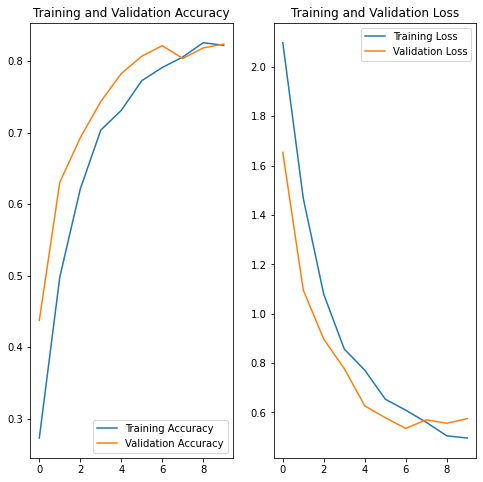

In [25]:
acc = vgghistory.history['accuracy']
val_acc = vgghistory.history['val_accuracy']

loss = vgghistory.history['loss']
val_loss = vgghistory.history['val_loss']

epochs_range = range(10)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
#vgg_model.save('vgg.h5')

In [26]:
y_pred1 = vgg_model.predict(validation_generator)
y_pred1 = np.argmax(y_pred1, axis=1)
y_pred1.sort()

In [27]:
cm1 = confusion_matrix(validation_generator.classes, y_pred1)


In [28]:
import itertools
def plot_confusion_matrix(cm, classes, normalize=True, title='Confusion matrix', cmap=plt.cm.Blues):
    plt.figure(figsize=(10,10))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90)
    plt.yticks(tick_marks, classes)
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        cm = np.around(cm, decimals=2)
        cm[np.isnan(cm)] = 0.0
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Normalized confusion matrix


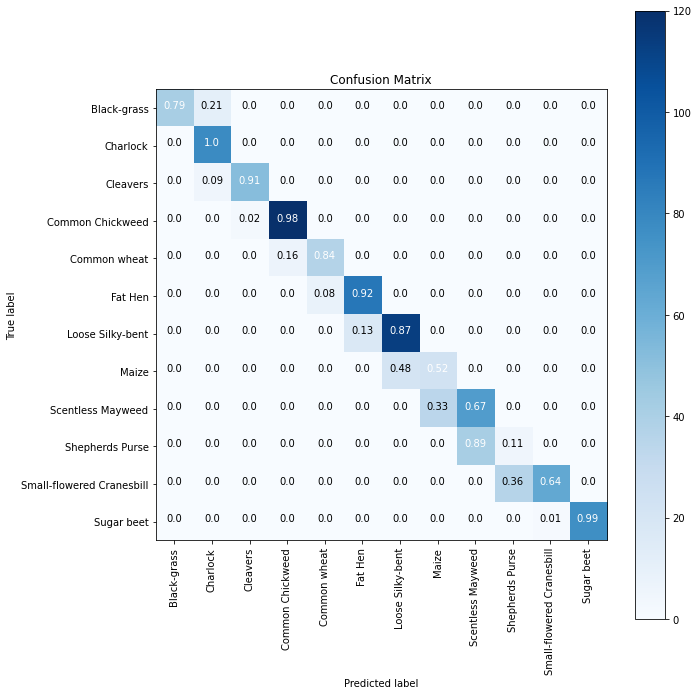

In [29]:
plot_confusion_matrix(cm1, classes, title='Confusion Matrix')

In [30]:
print(classification_report(validation_generator.classes, y_pred1,target_names = classes))

                           precision    recall  f1-score   support

              Black-grass       1.00      0.79      0.88        52
                 Charlock       0.83      1.00      0.91        78
                 Cleavers       0.96      0.91      0.94        57
         Common Chickweed       0.94      0.98      0.96       122
             Common wheat       0.82      0.84      0.83        44
                  Fat Hen       0.84      0.92      0.87        95
         Loose Silky-bent       0.84      0.87      0.86       130
                    Maize       0.40      0.52      0.46        44
        Scentless Mayweed       0.63      0.67      0.65       103
          Shepherds Purse       0.12      0.11      0.11        46
Small-flowered Cranesbill       0.98      0.64      0.77        99
               Sugar beet       1.00      0.99      0.99        77

                 accuracy                           0.81       947
                macro avg       0.78      0.77      0.77    

## RESNET

In [13]:

from tensorflow.keras.applications.resnet50 import ResNet50
base_model1 = ResNet50( input_shape = (img_height,img_width, 3),include_top = False, weights = 'imagenet')

2022-03-08 14:30:16.815498: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-03-08 14:30:16.907008: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-03-08 14:30:16.907708: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-03-08 14:30:16.908768: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compil

94781440/94765736 [==============================] - 2s 0us/step


#### 174 layers

In [14]:
# for i, layer in enumerate(base_model1.layers):
#     print(i, layer.name, layer.trainable)
    

for layer in base_model1.layers[:15]:
    layer.trainable = False

In [15]:
x1 = base_model1.output
x1 = layers.Flatten()(x1)
x1 = Dense(512, activation='relu')(x1)
x1 = layers.Dropout(0.5)(x1) 
x1 = Dense(256, activation='relu')(x1)

x1 = Dense(12, activation='softmax')(x1)
resnet_model = models.Model(inputs=base_model1.input, outputs=x1)


In [16]:
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
lr_reduce = ReduceLROnPlateau(monitor='val_accuracy', factor=0.05, patience=5, verbose=1, mode='max', min_lr=0.000002)

checkpoint = ModelCheckpoint('resnet.h5', monitor= 'val_accuracy', mode= 'max', save_best_only = True, verbose= 1)

early_stop=EarlyStopping(monitor='val_loss',mode='min',verbose=1,patience=5)
callbacklist = [lr_reduce,checkpoint,early_stop]

In [17]:
from tensorflow.keras import layers, models, Model, optimizers
learning_rate= 5e-5
resnet_model.compile(
    loss="categorical_crossentropy", 
    optimizer=optimizers.Adam(learning_rate=learning_rate), metrics=["accuracy"])


In [18]:
resnethistory = resnet_model.fit_generator(
    train_generator, 
    validation_data=validation_generator, 
    epochs=10, 
    shuffle=True, 
    callbacks = callbacklist,
    verbose=1)


/opt/conda/lib/python3.7/site-packages/keras/engine/training.py:1972: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  warnings.warn('`Model.fit_generator` is deprecated and '
2022-03-08 14:30:27.735287: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


Epoch 1/10


2022-03-08 14:30:33.586734: I tensorflow/stream_executor/cuda/cuda_dnn.cc:369] Loaded cuDNN version 8005


191/191 [==============================] - 165s 808ms/step - loss: 2.0792 - accuracy: 0.3879 - val_loss: 5.0151 - val_accuracy: 0.1373

Epoch 00001: val_accuracy improved from -inf to 0.13728, saving model to resnet.h5


/opt/conda/lib/python3.7/site-packages/keras/utils/generic_utils.py:497: CustomMaskWarning: Custom mask layers require a config and must override get_config. When loading, the custom mask layer must be passed to the custom_objects argument.
  category=CustomMaskWarning)


Epoch 2/10
191/191 [==============================] - 111s 584ms/step - loss: 0.8313 - accuracy: 0.7276 - val_loss: 3.6296 - val_accuracy: 0.1373

Epoch 00002: val_accuracy did not improve from 0.13728
Epoch 3/10
191/191 [==============================] - 110s 577ms/step - loss: 0.5915 - accuracy: 0.8025 - val_loss: 4.6474 - val_accuracy: 0.1373

Epoch 00003: val_accuracy did not improve from 0.13728
Epoch 4/10
191/191 [==============================] - 110s 575ms/step - loss: 0.4723 - accuracy: 0.8449 - val_loss: 5.6623 - val_accuracy: 0.0876

Epoch 00004: val_accuracy did not improve from 0.13728
Epoch 5/10
191/191 [==============================] - 131s 686ms/step - loss: 0.3857 - accuracy: 0.8669 - val_loss: 3.4809 - val_accuracy: 0.2735

Epoch 00005: val_accuracy improved from 0.13728 to 0.27350, saving model to resnet.h5
Epoch 6/10
191/191 [==============================] - 111s 583ms/step - loss: 0.3386 - accuracy: 0.8896 - val_loss: 0.7764 - val_accuracy: 0.7835

Epoch 00006: v

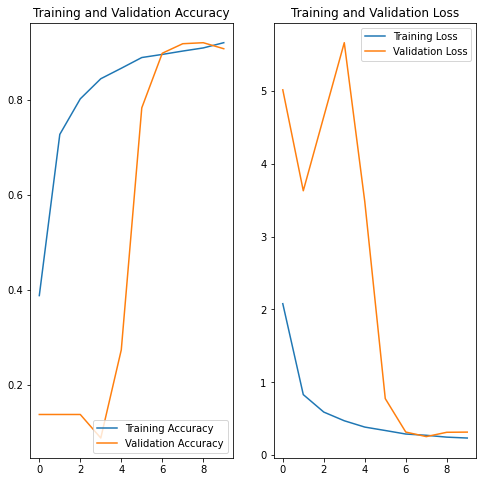

In [19]:
acc = resnethistory.history['accuracy']
val_acc = resnethistory.history['val_accuracy']

loss = resnethistory.history['loss']
val_loss = resnethistory.history['val_loss']

epochs_range = range(10)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [31]:
y_pred2 = resnet_model.predict(validation_generator)
y_pred2 = np.argmax(y_pred2, axis=1)
y_pred2.sort()


In [32]:
cm2 = confusion_matrix(validation_generator.classes, y_pred2)


Normalized confusion matrix


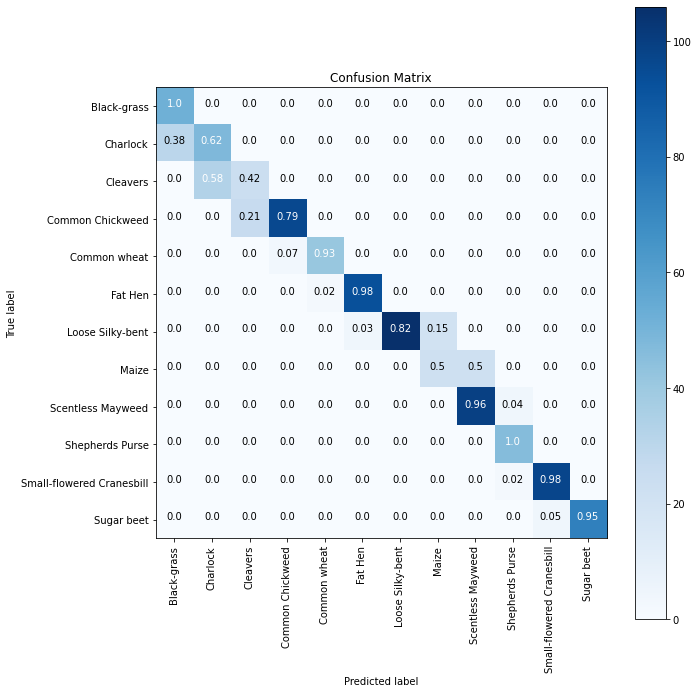

In [33]:
plot_confusion_matrix(cm2, classes, title='Confusion Matrix')


In [34]:
print(classification_report(validation_generator.classes, y_pred2,target_names = classes))


                           precision    recall  f1-score   support

              Black-grass       0.63      1.00      0.78        52
                 Charlock       0.59      0.62      0.60        78
                 Cleavers       0.48      0.42      0.45        57
         Common Chickweed       0.97      0.79      0.87       122
             Common wheat       0.95      0.93      0.94        44
                  Fat Hen       0.96      0.98      0.97        95
         Loose Silky-bent       1.00      0.82      0.90       130
                    Maize       0.52      0.50      0.51        44
        Scentless Mayweed       0.82      0.96      0.88       103
          Shepherds Purse       0.88      1.00      0.94        46
Small-flowered Cranesbill       0.96      0.98      0.97        99
               Sugar beet       1.00      0.95      0.97        77

                 accuracy                           0.84       947
                macro avg       0.81      0.83      0.82    

In [ ]:
#resnet_model.save('resnet.h5')

## Inception

In [35]:
from tensorflow.keras.applications.inception_v3 import InceptionV3
base_model2 = InceptionV3(input_shape = (img_height,img_width, 3), include_top = False, weights = 'imagenet')


87924736/87910968 [==============================] - 0s 0us/step


#### 310 layers

In [36]:
# for i, layer in enumerate(base_model2.layers):
#     print(i, layer.name, layer.trainable)

for layer in base_model2.layers[:15]:
    layer.trainable = False

# for i, layer in enumerate(base_model2.layers):
#     print(i, layer.name, layer.trainable)
#310 layers

In [37]:
x2 = base_model2.output
x2 = layers.Flatten()(x2)
x2 = Dense(512, activation='relu')(x2)
x2 = layers.Dropout(0.5)(x2) 
x2 = Dense(256, activation='relu')(x2)
x2 = Dense(12, activation='softmax')(x2) 
inc_model = models.Model(inputs=base_model2.input, outputs=x2)


In [39]:
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
lr_reduce = ReduceLROnPlateau(monitor='val_accuracy', factor=0.6, patience=5, verbose=1, mode='max', min_lr=5e-5)

checkpoint = ModelCheckpoint('./inc.h5', monitor= 'val_accuracy', mode= 'max', save_best_only = True, verbose= 1)
early_stop=EarlyStopping(monitor='val_loss',mode='min',verbose=1,patience=5)
callbacklist = [lr_reduce,early_stop,checkpoint]

In [40]:
from tensorflow.keras import layers, models, Model, optimizers
learning_rate= 5e-5
inc_model.compile(loss="categorical_crossentropy", optimizer=optimizers.Adam(learning_rate=learning_rate), metrics=["accuracy"])



In [41]:
inchistory = inc_model.fit_generator(
    train_generator, 
    validation_data=validation_generator, 
    epochs=10, 
    shuffle=True, 
    callbacks = callbacklist,
    verbose=1)


/opt/conda/lib/python3.7/site-packages/keras/engine/training.py:1972: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  warnings.warn('`Model.fit_generator` is deprecated and '


Epoch 1/10
191/191 [==============================] - 116s 573ms/step - loss: 2.1244 - accuracy: 0.2948 - val_loss: 1.1717 - val_accuracy: 0.6272

Epoch 00001: val_accuracy improved from -inf to 0.62724, saving model to ./inc.h5
Epoch 2/10
191/191 [==============================] - 110s 577ms/step - loss: 1.0579 - accuracy: 0.6487 - val_loss: 0.5493 - val_accuracy: 0.8194

Epoch 00002: val_accuracy improved from 0.62724 to 0.81943, saving model to ./inc.h5
Epoch 3/10
191/191 [==============================] - 129s 675ms/step - loss: 0.6441 - accuracy: 0.7852 - val_loss: 0.3779 - val_accuracy: 0.8775

Epoch 00003: val_accuracy improved from 0.81943 to 0.87751, saving model to ./inc.h5
Epoch 4/10
191/191 [==============================] - 107s 562ms/step - loss: 0.4901 - accuracy: 0.8393 - val_loss: 0.3813 - val_accuracy: 0.8817

Epoch 00004: val_accuracy improved from 0.87751 to 0.88173, saving model to ./inc.h5
Epoch 5/10
191/191 [==============================] - 108s 566ms/step - los

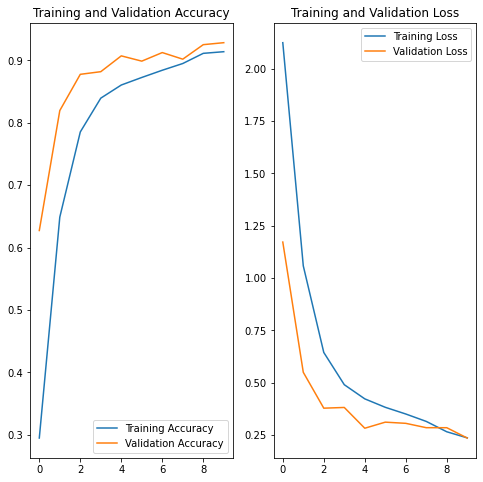

In [42]:
acc = inchistory.history['accuracy']
val_acc = inchistory.history['val_accuracy']

loss = inchistory.history['loss']
val_loss = inchistory.history['val_loss']

epochs_range = range(10)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()



In [43]:
y_pred3 = inc_model.predict(validation_generator)
y_pred3 = np.argmax(y_pred3, axis=1)
y_pred3.sort()

In [45]:
cm3 = confusion_matrix(validation_generator.classes, y_pred3)


Normalized confusion matrix


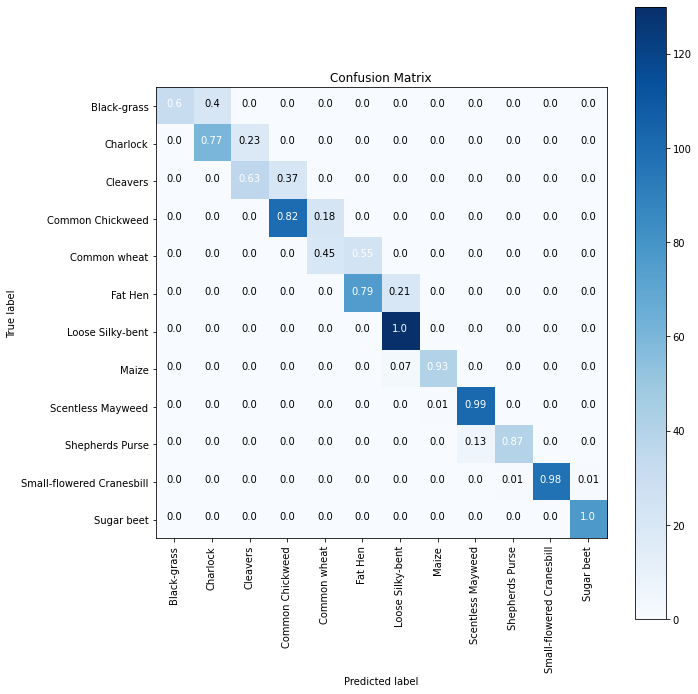

In [46]:
plot_confusion_matrix(cm3, classes, title='Confusion Matrix')

In [47]:
print(classification_report(validation_generator.classes, y_pred3,target_names = classes))

                           precision    recall  f1-score   support

              Black-grass       1.00      0.60      0.75        52
                 Charlock       0.74      0.77      0.75        78
                 Cleavers       0.67      0.63      0.65        57
         Common Chickweed       0.83      0.82      0.82       122
             Common wheat       0.48      0.45      0.47        44
                  Fat Hen       0.76      0.79      0.77        95
         Loose Silky-bent       0.85      1.00      0.92       130
                    Maize       0.98      0.93      0.95        44
        Scentless Mayweed       0.94      0.99      0.97       103
          Shepherds Purse       0.98      0.87      0.92        46
Small-flowered Cranesbill       1.00      0.98      0.99        99
               Sugar beet       0.99      1.00      0.99        77

                 accuracy                           0.85       947
                macro avg       0.85      0.82      0.83    

In [ ]:
#inc_model.save('inc.h5')